# Flood check: water quality (Water Quality Portal)

**Summary.** Enterococcus (median +6%, mean +15%) and turbidity (median +3%) rise after a flood and nitrate + nitrite falls slightly (median -4%), while E. coli, fecal coliform, phosphorus, suspended solids and nitrogen barely change; CRS and non-CRS zip-days move in the same direction by similar amounts.

Water-quality results (USGS NWIS + EPA WQX via the Water Quality Portal, 1990-2024) averaged per ZCTA and day. **Before** / **after** = geometric mean of the zip's daily medians in the 30 days before / after the date of loss (loss date excluded). One figure per parameter. Function: `wqp_flood_windows`.

For each FEMA NFIP zip-day (all claims in a zip code on one date of loss), the outcome before the flood is compared with the outcome after it, for all floods, for zip-days whose claims are all in CRS communities (`crs_treat = 1`) and for those with none (`crs_treat = 0`). Mixed zip-days are included in *all floods* only.

**Top:** distribution of the outcome before vs. after. **Bottom:** each zip-day's own change (dashed: no change; solid orange: median). These are raw comparisons, not adjusted for season, region or repeated floods, and zip-days from the same zip or storm are not independent.

**Caveat:** `crs_treat = 0` includes claims whose CRS class is missing in the source (37% of claims), so *non-CRS* partly means *CRS status unknown*. Data preparation is in `bin/data/ai2_dataset.py`; methods in `bin/data/METHODS.md`.

Median changes of exactly 0 for bacteria and phosphorus mostly reflect a single sample on each side at the same reported (often detection-limit) value; the bottom panels show the spread.

In [1]:
import os, sys
import numpy as np

# pipeline code: bin/data/ai2_dataset.py (data paths: AI2_DATA_DIR, default /Users/chang/data/ai2)
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'bin', 'data')))
import ai2_dataset as A

In [2]:
# --- plotting ---
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import gridspec
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.5
mpl.rcParams['axes.xmargin'] = 1
mpl.rcParams['xtick.labelsize'] = 'x-large'
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.major.width'] = 1.5
mpl.rcParams['ytick.labelsize'] = 'x-large'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.major.width'] = 1.5
mpl.rcParams['legend.frameon'] = False
%matplotlib inline

In [3]:
GROUPS = [('all floods', None), ('CRS', 1.), ('non-CRS', 0.)]


def select(crs, val):
    return np.ones(len(crs), dtype=bool) if val is None else (crs == val)


def summary(before, after, crs, log=True):
    """median before/after and paired change for all floods, CRS and non-CRS"""
    print(f"{'':12s} {'n':>8s} {'median before':>14s} {'median after':>13s} {'median change':>14s} {'mean change':>12s} {'up':>5s} {'down':>5s}")
    for name, val in GROUPS:
        s = select(crs, val)
        b, a = before[s], after[s]
        if log:
            pos = (b > 0) & (a > 0)
            b, a = b[pos], a[pos]
            d = np.log(a / b)
            med, mean = f'{np.expm1(np.median(d)):+.1%}', f'{np.expm1(d.mean()):+.1%}'
        else:
            d = a - b
            med, mean = f'{np.median(d):+.3f}', f'{d.mean():+.4f}'
        print(f"{name:12s} {len(d):8d} {np.median(b):14.3g} {np.median(a):13.3g} {med:>14s} {mean:>12s} "
              f"{(d > 0).mean():5.0%} {(d < 0).mean():5.0%}")


def plot_check(before, after, crs, xlabel, log=True, nbins=40):
    """top: outcome distribution before vs. after a flood loss;
    bottom: each zip-day's own change; columns: all floods, CRS, non-CRS"""
    fig = plt.figure(figsize=(18, 9))
    gs = gridspec.GridSpec(2, 3, hspace=0.35, wspace=0.08)
    for j, (name, val) in enumerate(GROUPS):
        s = select(crs, val)
        b, a = before[s], after[s]
        if log:
            pos = (b > 0) & (a > 0)
            b, a = b[pos], a[pos]

        # distribution before vs. after
        sub = plt.subplot(gs[0, j])
        lo, hi = np.percentile(np.concatenate([b, a]), [0.5, 99.5])
        bins = np.logspace(np.log10(lo), np.log10(hi), nbins+1) if log else np.linspace(lo, hi, nbins+1)
        _ = sub.hist(b, bins=bins, density=True, alpha=0.5, color='C0', label='before')
        _ = sub.hist(a, bins=bins, density=True, alpha=0.5, color='C1', label='after')
        _ = sub.hist(b, bins=bins, density=True, histtype='step', color='C0')
        _ = sub.hist(a, bins=bins, density=True, histtype='step', color='C1')
        if log: sub.set_xscale('log')
        sub.set_xlim(lo, hi)
        sub.set_ylim(0, 1.4 * sub.get_ylim()[1])   # room for the labels
        sub.set_yticks([])
        sub.text(0.04, 0.95, name, transform=sub.transAxes, ha='left', va='top', fontsize=22)
        sub.text(0.04, 0.82, r'$N=%s$' % f'{len(b):,}'.replace(',', '{,}'), transform=sub.transAxes,
                 ha='left', va='top', fontsize=15)
        if j == 0: sub.legend(loc='upper right', fontsize=20, handletextpad=0.2)
        if j == 1: sub.set_xlabel(xlabel, fontsize=22)

        # each zip-day's change
        sub = plt.subplot(gs[1, j])
        d = np.log(a / b) if log else a - b
        lim = np.percentile(np.abs(d), 99) or 1.
        _ = sub.hist(d, bins=60, range=(-lim, lim), alpha=0.5, color='C0')
        _ = sub.hist(d, bins=60, range=(-lim, lim), histtype='step', color='C0')
        sub.axvline(0., color='k', linestyle='--')
        sub.axvline(np.median(d), color='C1', linestyle='-', linewidth=2)
        sub.set_xlim(-lim, lim)
        sub.set_yscale('log')
        sub.set_ylim(0.7, 8 * sub.get_ylim()[1])    # room for the label
        sub.set_yticks([])
        sub.yaxis.set_minor_locator(mpl.ticker.NullLocator())
        chg = (r'median $%+.1f\%%$' % (100 * np.expm1(np.median(d)))) if log else (r'mean $%+.4f$' % d.mean())
        sub.text(0.96, 0.95, chg, transform=sub.transAxes, ha='right', va='top', fontsize=16)
        if j == 1:
            sub.set_xlabel(r'$\ln$(after / before)' if log else 'after $-$ before (per month)', fontsize=22)
    plt.show()

In [4]:
wqp = A.wqp_flood_windows(A.DATA_DIR)
for p, (b, a, c) in wqp.items(): print(f'{p:16s} {len(b):7,d} paired zip-days')

ecoli              8,677 paired zip-days
enterococcus      12,871 paired zip-days
fecal_coliform    20,155 paired zip-days
nitrate            9,859 paired zip-days
nitrate_nitrite    4,953 paired zip-days
nitrogen           4,956 paired zip-days
phosphorus        21,904 paired zip-days
tss               27,195 paired zip-days
turbidity         30,804 paired zip-days


## turbidity

In [5]:
before, after, crs = wqp['turbidity']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods      30804           7.47             8          +2.9%        +5.7%   51%   48%
CRS             16241           4.92          5.17          +3.1%        +5.1%   52%   47%
non-CRS         13119             14          15.4          +2.5%        +5.9%   51%   48%


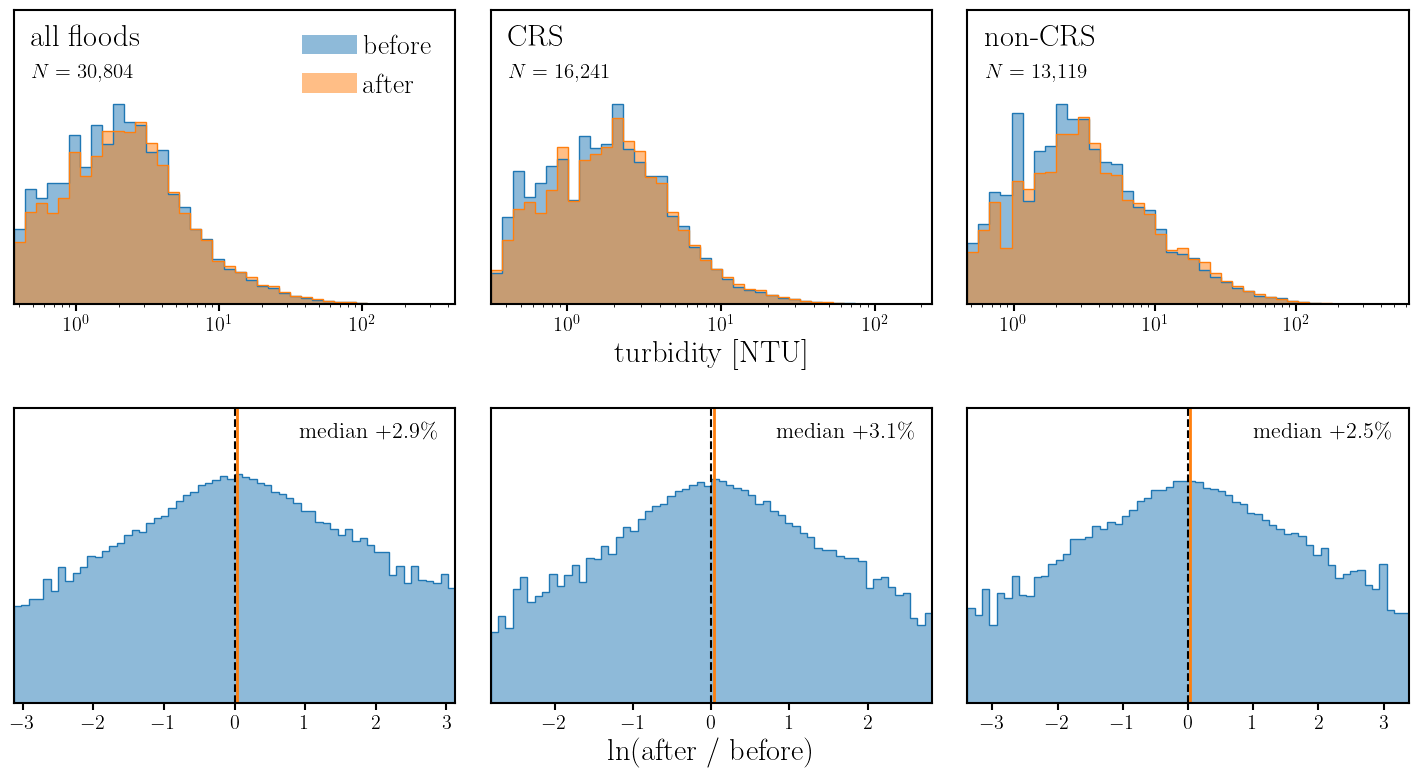

In [6]:
plot_check(before, after, crs, r'turbidity [NTU]')

## tss

In [7]:
before, after, crs = wqp['tss']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods      27195           14.5          14.6          -1.3%        -1.5%   48%   50%
CRS             13416           12.1            12          -2.3%        -1.9%   47%   51%
non-CRS         12435             18            18          +0.0%        -0.9%   48%   50%


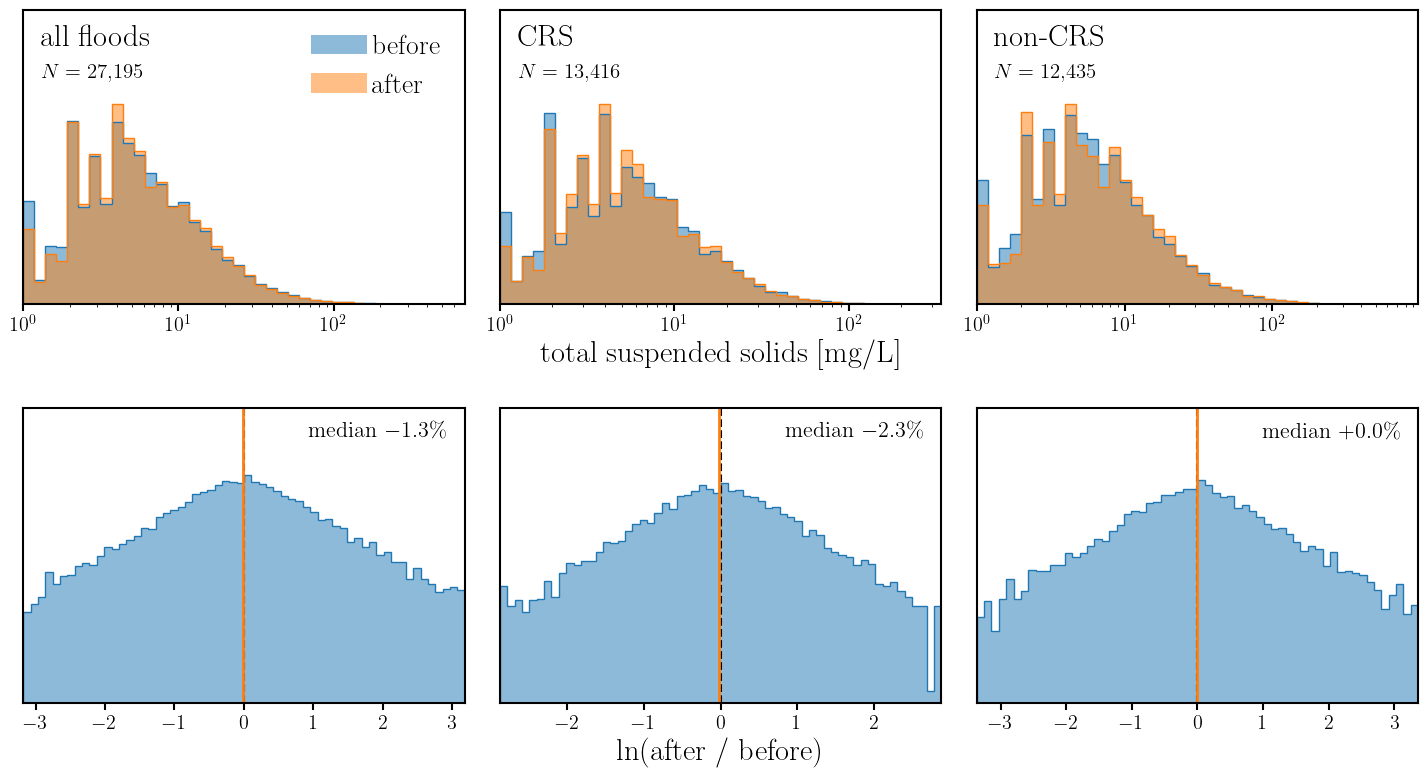

In [8]:
plot_check(before, after, crs, r'total suspended solids [mg/L]')

## ecoli

In [9]:
before, after, crs = wqp['ecoli']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods       8677            117           120          +0.0%        +5.0%   50%   48%
CRS              3672            130           125          +0.0%        +4.3%   50%   48%
non-CRS          4610            111           120          +0.0%        +5.4%   50%   48%


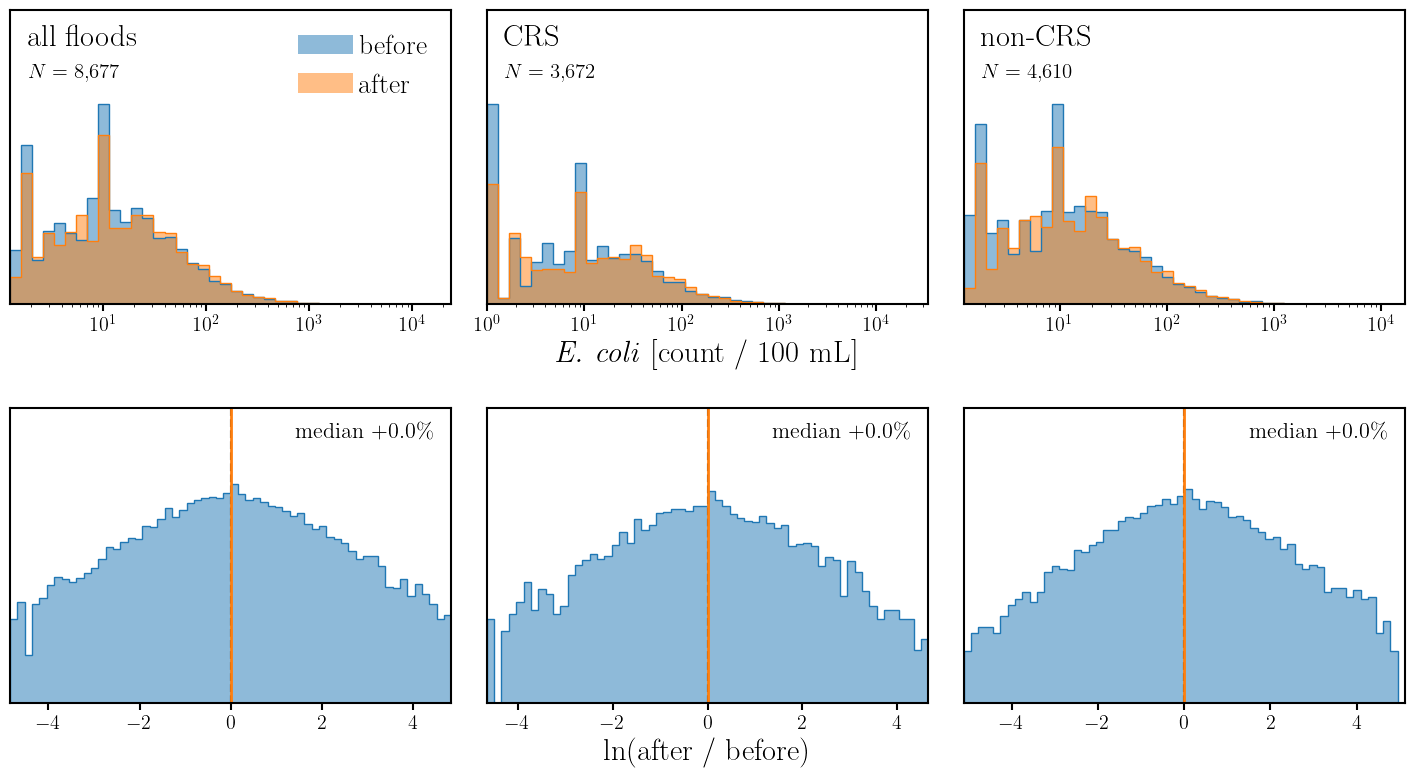

In [10]:
plot_check(before, after, crs, r'\textit{E. coli} [count / 100 mL]')

## fecal coliform

In [11]:
before, after, crs = wqp['fecal_coliform']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods      20155             51          54.8          +0.0%        +7.4%   49%   47%
CRS             12033             38          40.4          +0.0%        +5.3%   49%   47%
non-CRS          7079           82.5            90          +3.6%       +11.7%   51%   47%


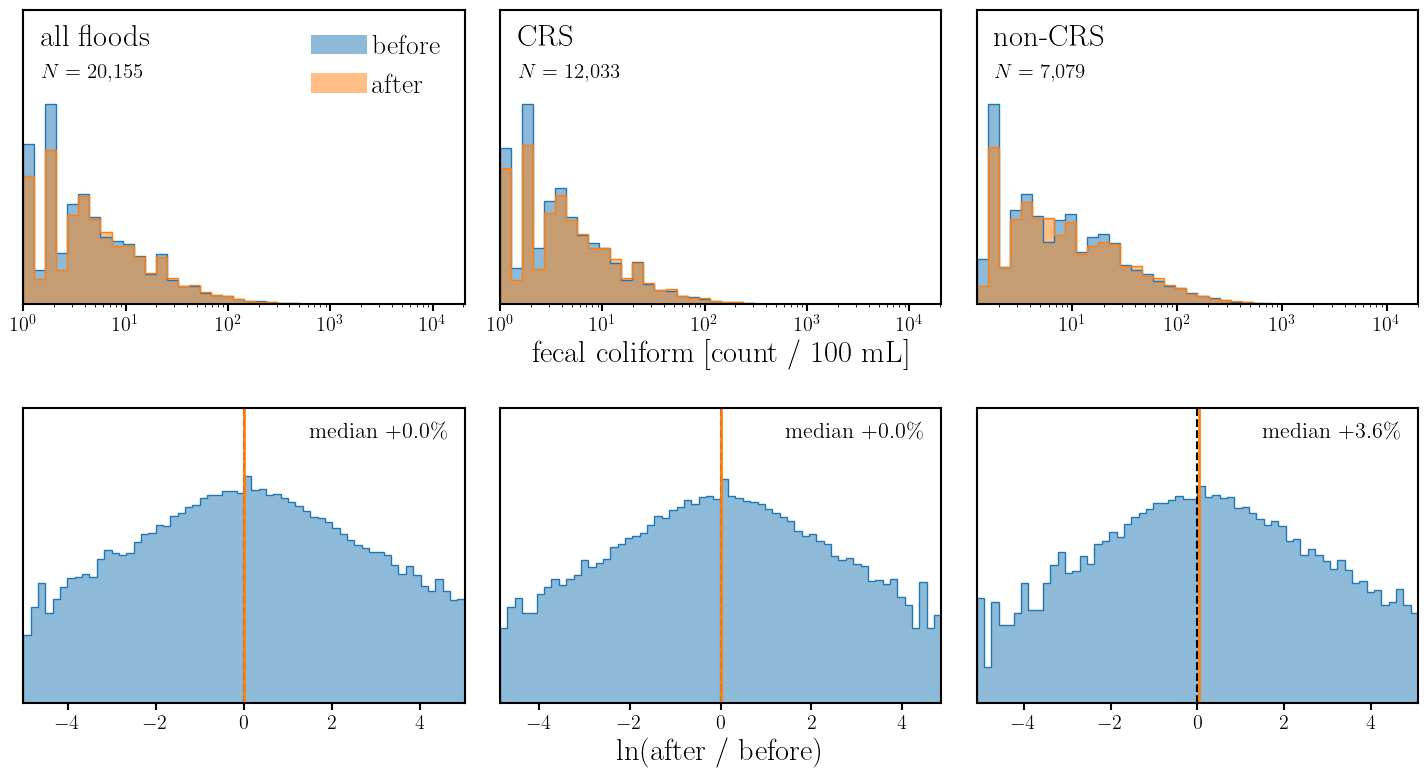

In [12]:
plot_check(before, after, crs, r'fecal coliform [count / 100 mL]')

## enterococcus

In [13]:
before, after, crs = wqp['enterococcus']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods      12871           15.4          18.9          +6.1%       +14.5%   52%   43%
CRS              9031           14.3          17.5          +5.2%       +15.1%   52%   43%
non-CRS          3256           18.6          22.9          +8.1%       +13.7%   53%   44%


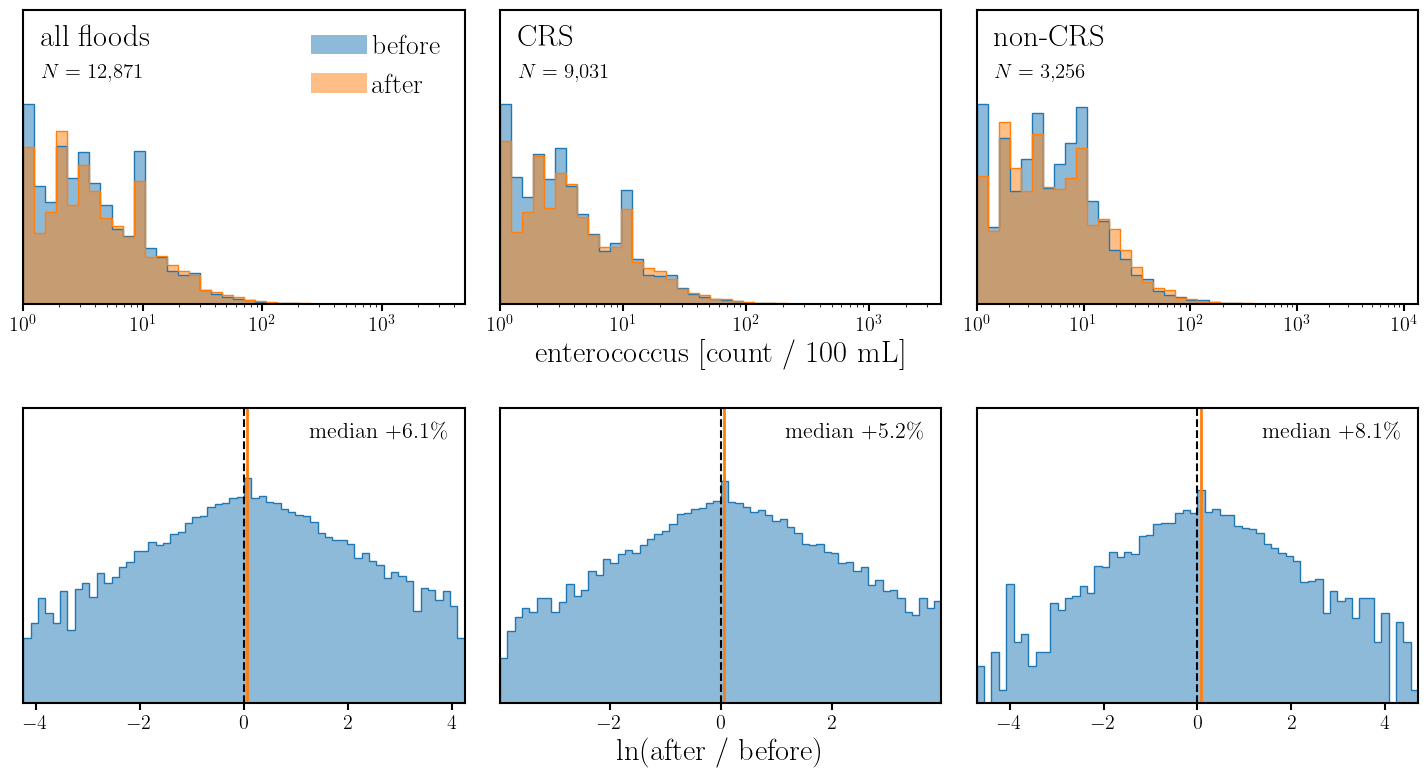

In [14]:
plot_check(before, after, crs, r'enterococcus [count / 100 mL]')

## phosphorus

In [15]:
before, after, crs = wqp['phosphorus']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods      21904          0.115         0.118          +0.0%        -1.3%   49%   49%
CRS              9100          0.111         0.117          +0.0%        -1.9%   50%   48%
non-CRS         11786          0.115         0.119          +0.0%        -0.8%   48%   49%


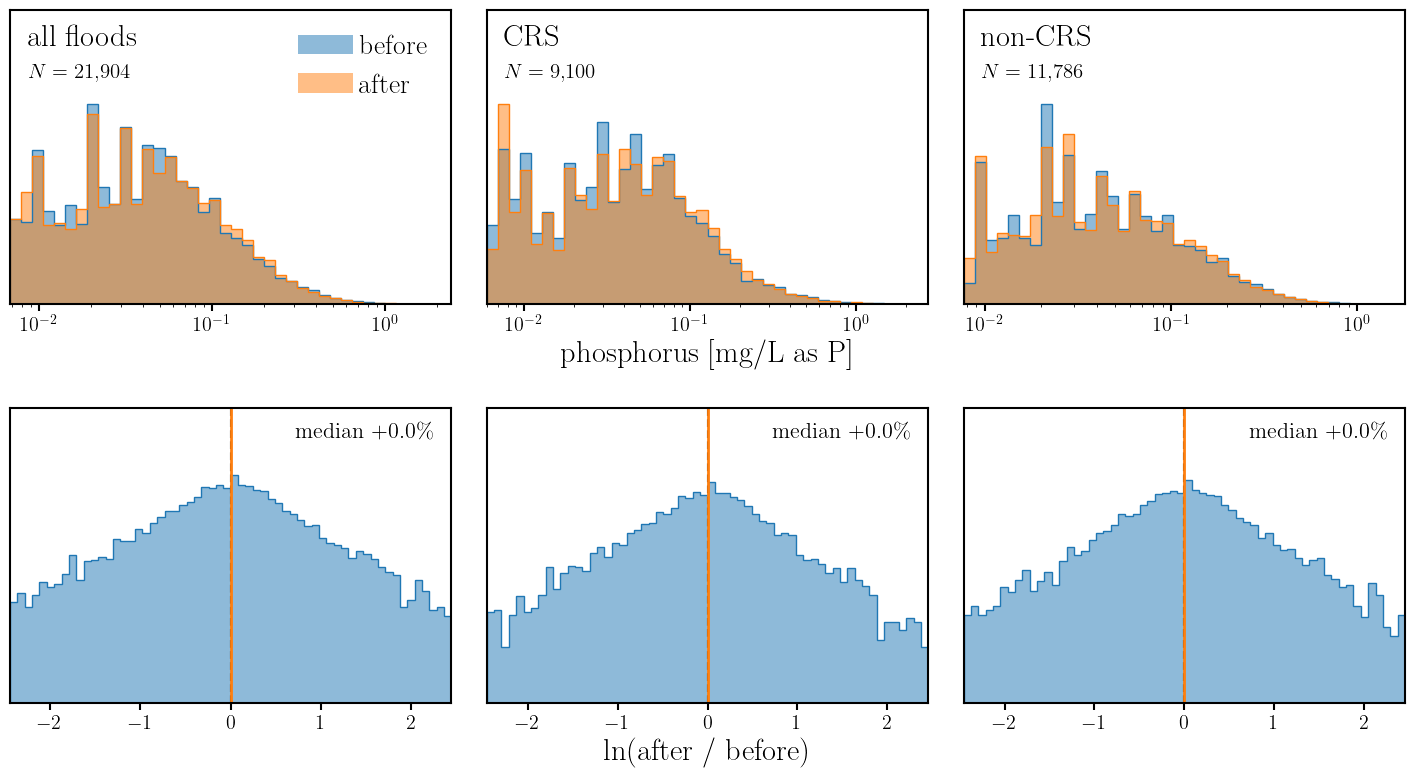

In [16]:
plot_check(before, after, crs, r'phosphorus [mg/L as P]')

## nitrogen

In [17]:
before, after, crs = wqp['nitrogen']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods       4956           0.71          0.76          +1.1%        -0.2%   51%   48%
CRS              1640           0.77         0.831          -0.1%        -1.9%   49%   50%
non-CRS          3143          0.697         0.717          +1.4%        +0.4%   51%   47%


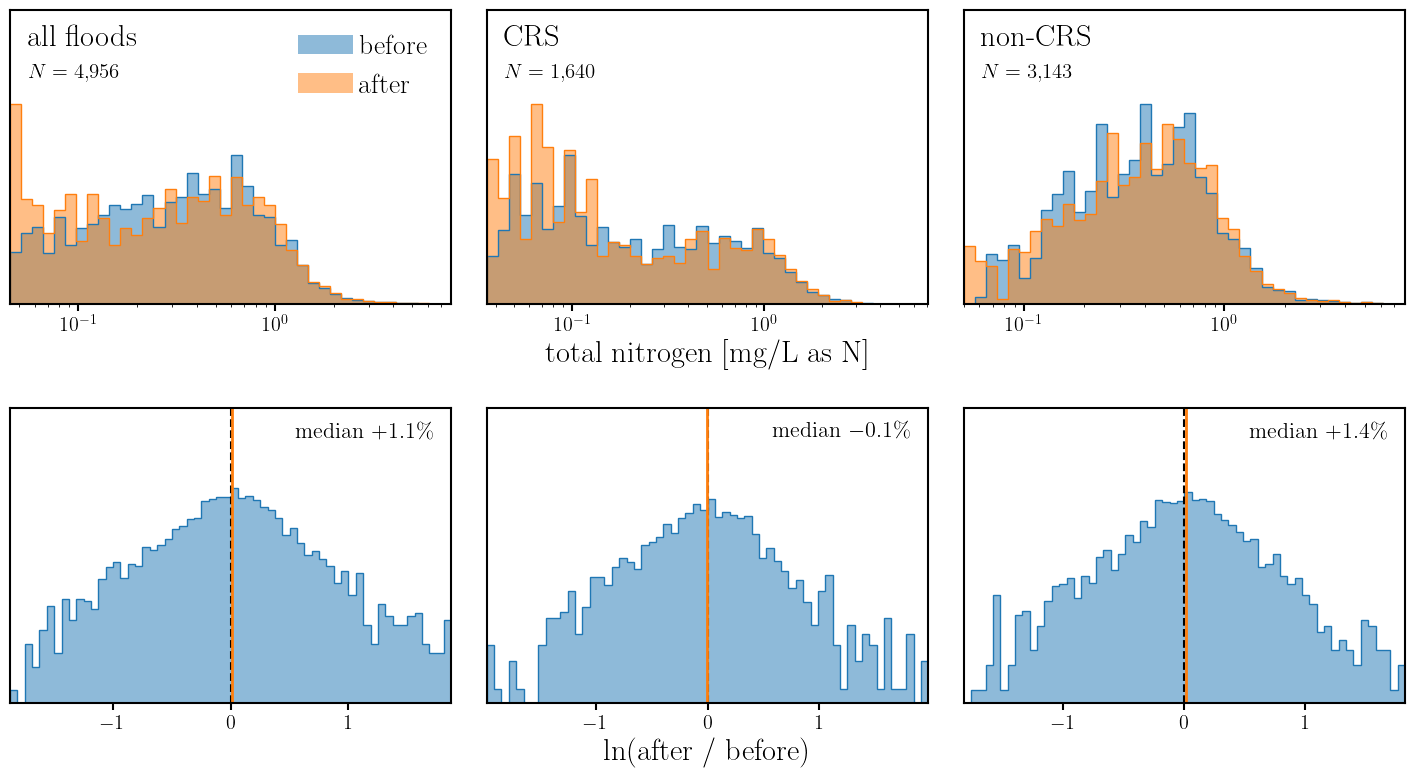

In [18]:
plot_check(before, after, crs, r'total nitrogen [mg/L as N]')

## nitrate nitrite

In [19]:
before, after, crs = wqp['nitrate_nitrite']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods       4953          0.656          0.61          -4.2%        -7.7%   45%   54%
CRS              1470          0.501         0.462          -5.6%        -4.9%   45%   54%
non-CRS          3272          0.765         0.701          -3.5%        -8.0%   46%   53%


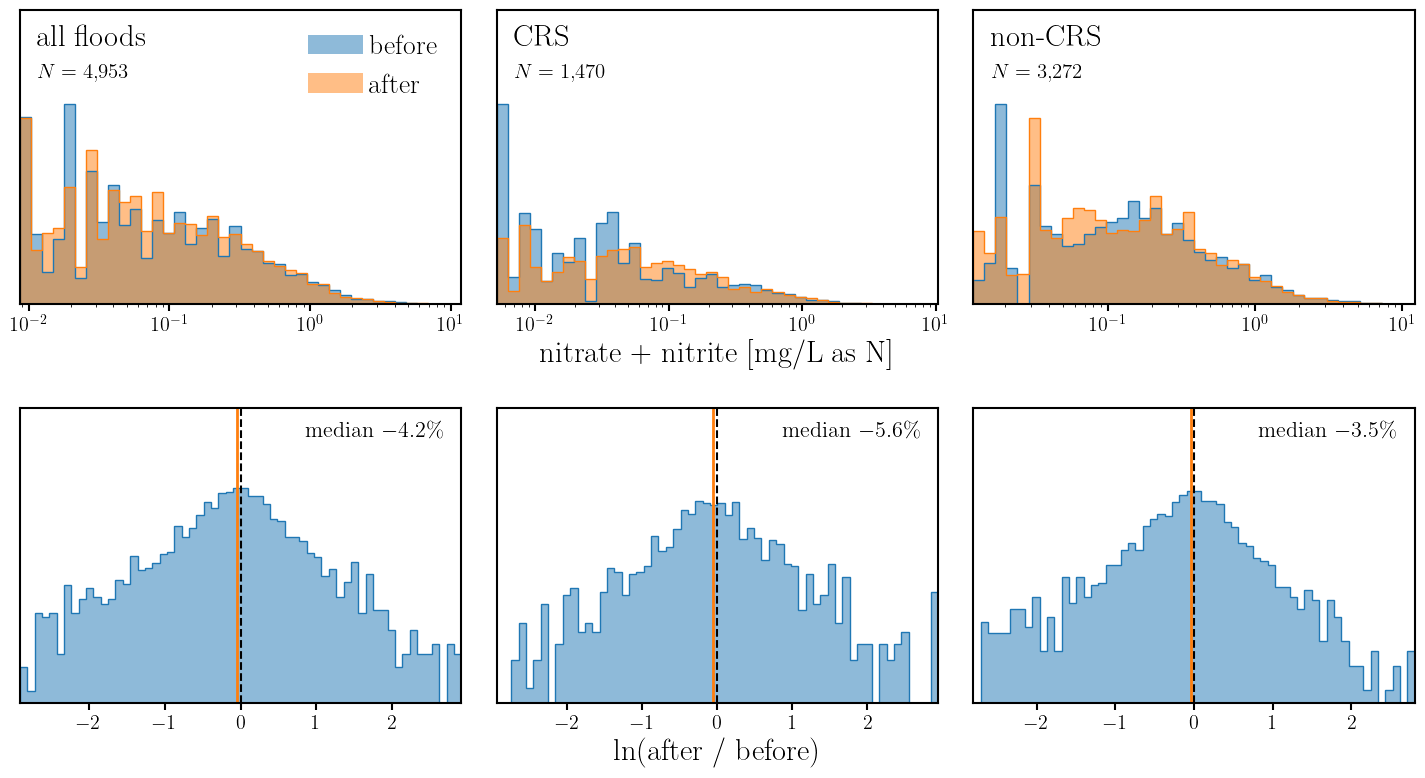

In [20]:
plot_check(before, after, crs, r'nitrate + nitrite [mg/L as N]')

## nitrate

In [21]:
before, after, crs = wqp['nitrate']
summary(before, after, crs)

                    n  median before  median after  median change  mean change    up  down
all floods       9859           0.67         0.625          +0.0%        +2.7%   49%   49%
CRS              4278           0.33         0.334          +0.9%        +4.9%   50%   48%
non-CRS          5204          0.868         0.824          +0.0%        +1.9%   49%   50%


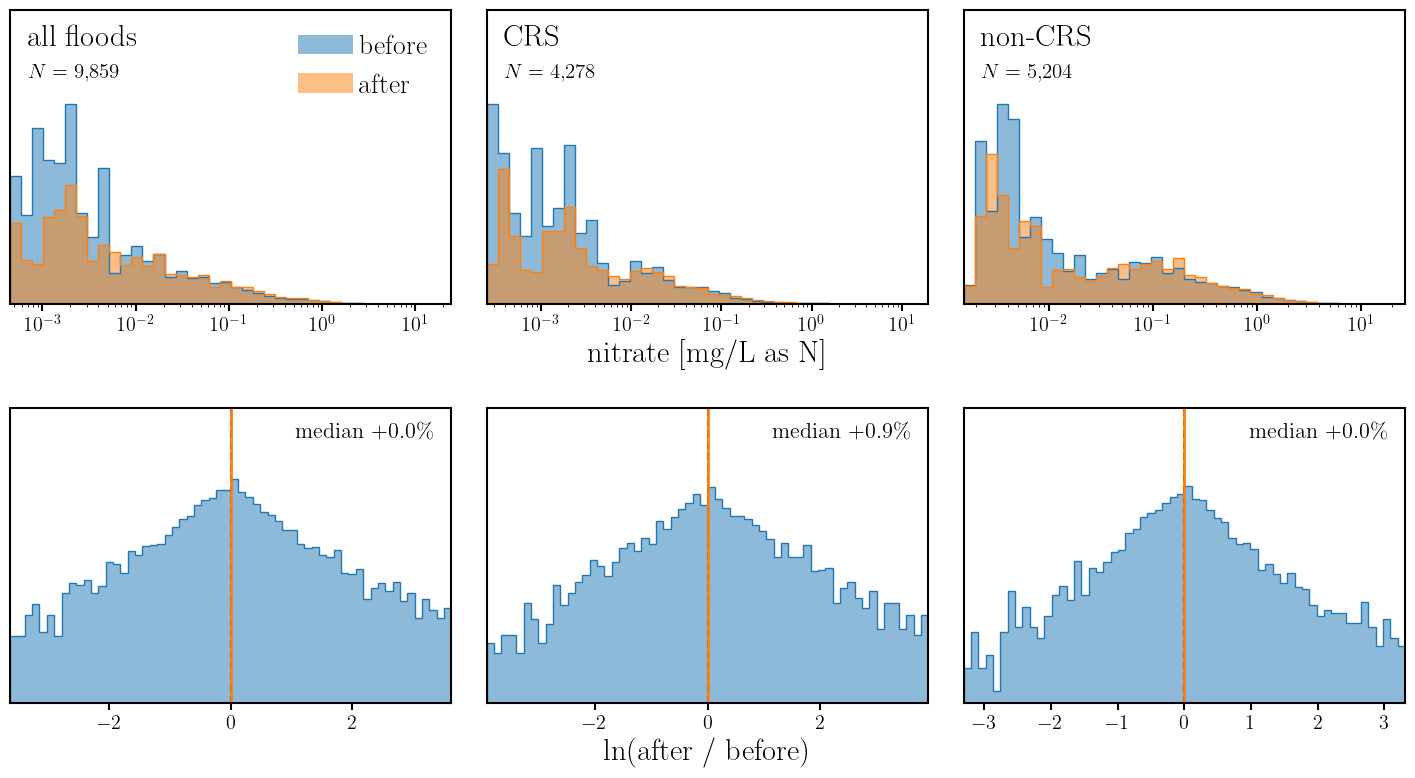

In [22]:
plot_check(before, after, crs, r'nitrate [mg/L as N]')